# Visualize Last-Layer Attention Matrices Across Inputs

This Visualize notebook loads the cached data produced by `Generate-last-layer-attention-matrices-across-inputs.ipynb` and presents head-averaged last-layer attention matrices for representative sequences from the main numerical input families at $N = 500$ using Llama-3.2-3B, as presented under **Attention-Induced Token Graphs: Construction and Visualization Robustness** in the appendix.

Import dependencies and define heatmap settings.

In [1]:
import re
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

# 500-token analysis window
REFERENCE_CONTEXT_TOKENS = 1000
ANALYSIS_CONTEXT_TOKENS = 500
CONTEXT_FRAC = ANALYSIS_CONTEXT_TOKENS / REFERENCE_CONTEXT_TOKENS
CONTEXT_DISPLAY_LABEL = f'{ANALYSIS_CONTEXT_TOKENS} tokens'
ATTENTION_DATA_DIR = Path('processed_last_layer_attention_data')
FIGURE_OUTPUT_DIR = Path('figure')

# Matrix selection and shared heatmap styling
HEAD_INDEX = None  # None plots the mean over heads; use one-based head ids to plot a single head.
HEATMAP_TRANSFORM = 'log10'
HEATMAP_EPS = 1e-8
HEATMAP_PERCENTILE_LIMITS = (0.5, 99.8)
ATTENTION_CMAP_NAME = 'magma'
ZERO_ATTENTION_COLOR = '#F2F2F2'
DIAGONAL_LINE_COLOR = '#FFFFFF'
TOKEN_MARKER_LABELS_ONE_BASED = np.array([1, 100, 200, 300, 400, ANALYSIS_CONTEXT_TOKENS], dtype=int)

# Figure layout
FIGURE_SIZE = (18.4, 7.6)
DISPLAY_DPI = 150
PDF_DPI = 300
SUBPLOT_ADJUST = dict(left=0.064, right=0.922, bottom=0.100, top=0.900, wspace=0.115, hspace=0.245)
SAVEFIG_PAD_INCHES = 0.035
PANEL_TITLE_FONT_SIZE = 15
PANEL_TITLE_PAD = 5.0
PANEL_TITLE_LINESPACING = 0.95
PANEL_TITLE_Y_OFFSET = 0.004
AXIS_LABEL_FONT_SIZE = 15
TICK_LABEL_FONT_SIZE = 10
COLORBAR_AX_BOUNDS = [0.946, 0.19, 0.014, 0.62]

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = DISPLAY_DPI
plt.rcParams['savefig.dpi'] = PDF_DPI


In [2]:
# Input-family order, panel labels, and cache schema
DATA_ORDER = [
    'Constant 500',
    'Logistic r=3.2',
    'Logistic r=3.5',
    'Logistic r=3.55',
    'Logistic r=3.566',
    'Logistic r=3.5692',
    'Logistic r=3.5698',
    'Logistic r=3.9',
    'Logistic r=4.0',
    'Lorenz',
]

DATA_TITLE_OVERRIDES = {
    'Constant 500': 'Constant sequence',
}

DATA_TITLE_SUFFIXES = {
    'Logistic r=3.2': 'period 2',
    'Logistic r=3.5': 'period 4',
    'Logistic r=3.55': 'period 8',
    'Logistic r=3.566': 'period 16',
    'Logistic r=3.5692': 'period 32',
    'Logistic r=3.5698': 'period 64',
    'Logistic r=3.9': 'chaotic',
    'Logistic r=4.0': 'chaotic',
    'Lorenz': 'chaotic',
}

ATTENTION_DATA_ARRAY_KEYS = (
    'schema_version',
    'model_name',
    'data_name',
    'reference_context_tokens',
    'analysis_context_tokens',
    'context_frac',
    'ctx_len',
    'drop_bos',
    'renormalize_after_drop',
    'layer_index',
    'layer_index_zero_based',
    'num_model_layers',
    'num_heads',
    'token_start',
    'token_ids',
    'token_texts',
    'is_delimiter',
    'input_values',
    'attention_heads',
    'attention_mean',
)


def panel_title(data_name):
    data_name = str(data_name)
    title = DATA_TITLE_OVERRIDES.get(data_name, data_name)
    suffix = DATA_TITLE_SUFFIXES.get(data_name)
    return f'{title} ({suffix})' if suffix else title


def context_display_label(num_tokens=ANALYSIS_CONTEXT_TOKENS):
    return f'{int(num_tokens)} tokens'


def context_fraction_label(frac):
    pct = int(round(100 * float(frac)))
    return f'context{pct}'


def safe_data_stem(data_name, frac):
    name = str(data_name).replace('=', '_').replace('.', '_')
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return f'{name}_{context_fraction_label(frac)}'


def attention_data_path(data_name, frac=CONTEXT_FRAC, data_dir=ATTENTION_DATA_DIR):
    return Path(data_dir) / f'{safe_data_stem(data_name, frac)}_last_layer_attention.npz'


# Require the exact schema to catch stale or incompatible public caches
def load_last_layer_attention_data(data_name, frac=CONTEXT_FRAC, data_dir=ATTENTION_DATA_DIR):
    path = attention_data_path(data_name, frac=frac, data_dir=data_dir)
    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as npz:
        processed_data = {key: npz[key] for key in npz.files}

    missing = [key for key in ATTENTION_DATA_ARRAY_KEYS if key not in processed_data]
    if missing:
        raise KeyError(f'{path} is missing required arrays: {missing}')
    extra = sorted(set(processed_data) - set(ATTENTION_DATA_ARRAY_KEYS))
    if extra:
        raise KeyError(f'{path} contains unexpected arrays: {extra}')
    return processed_data


# Verify every expected input archive before plotting
def check_last_layer_attention_data(data_names=DATA_ORDER, frac=CONTEXT_FRAC, data_dir=ATTENTION_DATA_DIR):
    missing = []
    invalid = []
    for data_name in data_names:
        path = attention_data_path(data_name, frac=frac, data_dir=data_dir)
        if not path.exists():
            missing.append(path)
            continue
        try:
            load_last_layer_attention_data(data_name, frac=frac, data_dir=data_dir)
        except (OSError, KeyError, ValueError) as exc:
            invalid.append((path, exc))

    if missing:
        raise FileNotFoundError('Missing last-layer attention data:\n' + '\n'.join(str(path) for path in missing))
    if invalid:
        details = '\n'.join(f'{path}: {exc}' for path, exc in invalid)
        raise ValueError('Invalid last-layer attention data:\n' + details)


Select cached matrices, apply the display transform, and compute shared color limits.

In [3]:
def select_attention_matrix(processed_data, head_index=HEAD_INDEX):
    if head_index is None:
        # The appendix figure uses the mean over attention heads
        label = 'mean over heads'
        return np.asarray(processed_data['attention_mean'], dtype=np.float32), label

    n_heads = int(np.asarray(processed_data['num_heads']).item())
    head_one_based = int(head_index)
    if head_one_based < 1 or head_one_based > n_heads:
        raise ValueError(f'HEAD_INDEX must be in one-based range 1..{n_heads}, got {head_one_based}.')
    label = f'head {head_one_based}'
    return np.asarray(processed_data['attention_heads'], dtype=np.float32)[head_one_based - 1], label


def transform_attention_for_heatmap(A, mode=HEATMAP_TRANSFORM, eps=HEATMAP_EPS):
    A = np.asarray(A, dtype=float)
    if A.ndim != 2 or A.shape[0] != A.shape[1]:
        raise ValueError('Attention matrix must be square.')
    if str(mode).lower() == 'linear':
        return np.ma.masked_where(A <= 0, A)
    if str(mode).lower() == 'log10':
        return np.ma.masked_where(A <= 0, np.log10(np.clip(A, float(eps), None)))
    raise ValueError("HEATMAP_TRANSFORM must be 'linear' or 'log10'.")


def collect_attention_panel_data_for_global_norm(
    frac=CONTEXT_FRAC,
    data_names=DATA_ORDER,
    data_dir=ATTENTION_DATA_DIR,
    head_index=HEAD_INDEX,
    percentile_limits=HEATMAP_PERCENTILE_LIMITS,
):
    panel_data = []
    all_values = []
    matrix_label = None

    # Load every panel before fixing one color scale across input families
    for data_name in data_names:
        processed_data = load_last_layer_attention_data(data_name, frac=frac, data_dir=data_dir)
        attention_matrix, matrix_label = select_attention_matrix(processed_data, head_index=head_index)
        heatmap_values = transform_attention_for_heatmap(attention_matrix)
        compressed = heatmap_values.compressed()
        compressed = compressed[np.isfinite(compressed)]
        if compressed.size:
            all_values.append(compressed)

        panel_data.append(
            dict(
                data_name=data_name,
                layer_index=int(np.asarray(processed_data['layer_index']).item()),
                num_heads=int(np.asarray(processed_data['num_heads']).item()),
                attention_matrix=attention_matrix,
                heatmap_values=heatmap_values,
                token_ids=np.asarray(processed_data['token_ids'], dtype=np.int64),
                is_delimiter=np.asarray(processed_data['is_delimiter'], dtype=bool),
            )
        )

    if not all_values:
        heatmap_limits = (0.0, 1.0)
    else:
        all_values = np.concatenate(all_values)
        lo, hi = (float(value) for value in percentile_limits)
        heatmap_limits = tuple(float(value) for value in np.percentile(all_values, [lo, hi]))
        if heatmap_limits[0] >= heatmap_limits[1]:
            heatmap_limits = (float(np.min(all_values)), float(np.max(all_values)))

    return panel_data, heatmap_limits, matrix_label


Define token-axis formatting and assemble the multi-panel attention heatmap.

In [4]:
def token_marker_indices_and_labels(n, marker_labels_one_based=TOKEN_MARKER_LABELS_ONE_BASED):
    marker_labels = np.asarray(marker_labels_one_based, dtype=int)
    valid = (marker_labels >= 1) & (marker_labels <= int(n))
    marker_labels = marker_labels[valid]
    marker_indices = marker_labels - 1
    return marker_indices.astype(int), marker_labels.astype(int)


def add_row_aligned_panel_titles(fig, axes, titles, ncols=5):
    fig.canvas.draw()
    for row_start in range(0, len(titles), ncols):
        row_axes = axes[row_start:row_start + ncols]
        row_titles = titles[row_start:row_start + ncols]
        title_y = row_axes[0].get_position().y1 + PANEL_TITLE_Y_OFFSET
        for ax, title in zip(row_axes, row_titles):
            pos = ax.get_position()
            fig.text(
                pos.x0 + 0.5 * pos.width,
                title_y,
                title,
                ha='center',
                va='bottom',
                fontsize=PANEL_TITLE_FONT_SIZE,
            )


def style_attention_axis(ax, n):
    marker_indices, marker_labels = token_marker_indices_and_labels(n)
    ax.set_xticks(marker_indices)
    ax.set_xticklabels([str(int(label)) for label in marker_labels], fontsize=TICK_LABEL_FONT_SIZE)
    ax.set_yticks(marker_indices)
    ax.set_yticklabels([str(int(label)) for label in marker_labels], fontsize=TICK_LABEL_FONT_SIZE)
    ax.tick_params(axis='both', which='both', length=2.5, width=0.45, pad=1.5)
    ax.plot([-0.5, n - 0.5], [-0.5, n - 0.5], color=DIAGONAL_LINE_COLOR, linewidth=0.50, alpha=0.72)
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    for spine in ax.spines.values():
        spine.set_linewidth(0.45)
        spine.set_color('#222222')


def plot_last_layer_attention_matrices_across_inputs(
    frac=CONTEXT_FRAC,
    data_names=DATA_ORDER,
    data_dir=ATTENTION_DATA_DIR,
    figure_output_dir=FIGURE_OUTPUT_DIR,
    save=False,
    save_filename='last_layer_attention_matrices.pdf',
    show=True,
    head_index=HEAD_INDEX,
):
    # Compute one shared scale before drawing any panels
    panel_data, heatmap_limits, matrix_label = collect_attention_panel_data_for_global_norm(
        frac=frac,
        data_names=data_names,
        data_dir=data_dir,
        head_index=head_index,
    )
    vmin, vmax = heatmap_limits

    # Show masked zero-attention entries with a neutral background
    cmap = mpl.colormaps.get_cmap(ATTENTION_CMAP_NAME).copy()
    cmap.set_bad(ZERO_ATTENTION_COLOR)

    fig, axes = plt.subplots(2, 5, figsize=FIGURE_SIZE, dpi=DISPLAY_DPI)
    axes = np.asarray(axes).ravel()
    panel_titles = [panel_title(payload['data_name']) for payload in panel_data]
    image = None

    for ax, payload, title in zip(axes, panel_data, panel_titles):
        image = ax.imshow(
            payload['heatmap_values'],
            origin='upper',
            interpolation='nearest',
            aspect='equal',
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            rasterized=True,
        )
        style_attention_axis(ax, int(payload['attention_matrix'].shape[0]))
        ax.set_title(
            title,
            fontsize=PANEL_TITLE_FONT_SIZE,
            pad=PANEL_TITLE_PAD,
            linespacing=PANEL_TITLE_LINESPACING,
        )

    for ax in axes[len(panel_data):]:
        ax.axis('off')

    fig.subplots_adjust(**SUBPLOT_ADJUST)
    fig.text(0.495, 0.047, 'Key position', ha='center', va='center', fontsize=AXIS_LABEL_FONT_SIZE)
    fig.text(0.043, 0.505, 'Query position', ha='center', va='center', rotation='vertical', fontsize=AXIS_LABEL_FONT_SIZE)

    if image is not None:
        colorbar_ax = fig.add_axes(COLORBAR_AX_BOUNDS)
        colorbar = fig.colorbar(image, cax=colorbar_ax)
        colorbar.set_label('log10 attention weight', fontsize=AXIS_LABEL_FONT_SIZE)
        colorbar.ax.tick_params(labelsize=TICK_LABEL_FONT_SIZE)

    if save:
        figure_output_dir = Path(figure_output_dir)
        figure_output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_output_dir / str(save_filename), bbox_inches='tight', pad_inches=SAVEFIG_PAD_INCHES, dpi=PDF_DPI)

    if show:
        plt.show()

    return fig


Validate caches, display the head-averaged 500-token matrices, and save the PDF figure.

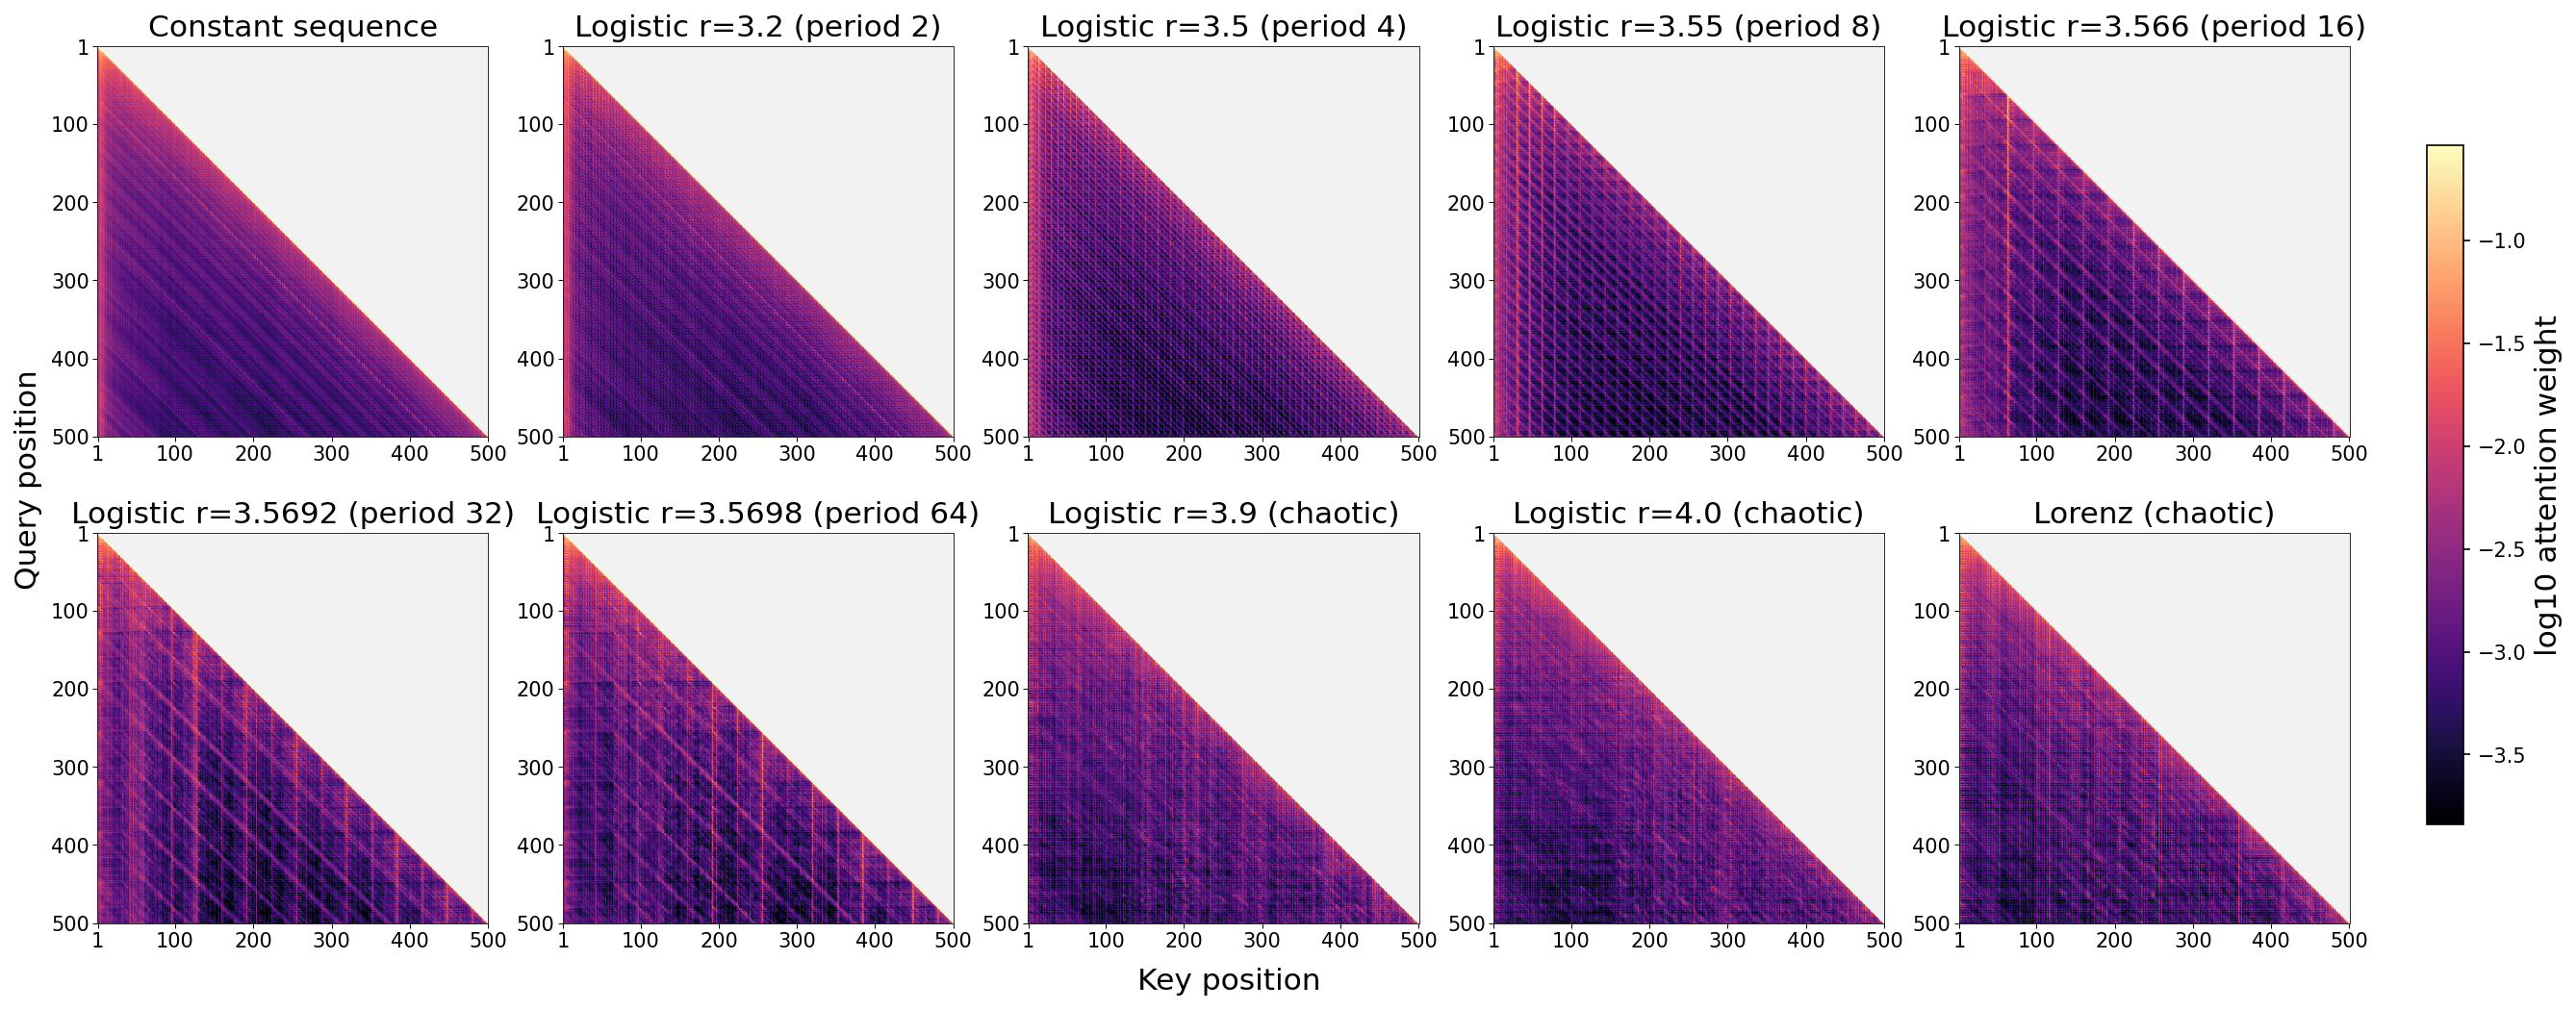

In [5]:
check_last_layer_attention_data()

plot_last_layer_attention_matrices_across_inputs(
    frac=CONTEXT_FRAC,
    save=True,
    show=True,
);
